# 🔍 Evaluation Dataset Viewer & Inspection

This notebook provides visual and quantitative inspection of the **evaluation dataset**:
- **Images**: `dataset/images/eval` (10 images: `drive_051.jpg` -> `drive_060.jpg`)
- **Labels**: `dataset/labels/eval` (10 YOLO ground-truth files: `drive_051.txt` -> `drive_060.txt`)
- **Class definitions**: `data.yaml` (`0: car`, `1: truck`, `2: bus`, `3: van`)

### Sections:
1. **Setup & Config**: Load class mapping and setup palettes.
2. **Dataset Loading**: Parse normalized YOLO annotations into pixel coordinates.
3. **Summary & Class Distribution**: Image-level statistics and class histogram.
4. **Multi-Image Grid View**: 2x5 overview grid of all 10 evaluation scenes with ground-truth boxes.
5. **Single-Image Detailed Inspector**: High-resolution zoom and box coordinate table for any image.
6. **Self-QC Validation Check**: Automated boundary and format verification.

## 1. Setup & Configuration
Load class names from `data.yaml` and configure visualization colors.

In [41]:
import os
from pathlib import Path
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

# 1. Define Paths
BASE_DIR = Path(".")
DATA_YAML = BASE_DIR / "data.yaml"
EVAL_IMAGES_DIR = BASE_DIR / "dataset/images/eval"
EVAL_LABELS_DIR = BASE_DIR / "dataset/labels/eval"

# 2. Load Class Names from data.yaml
if DATA_YAML.exists():
    with open(DATA_YAML, "r", encoding="utf-8") as f:
        data_cfg = yaml.safe_load(f)
    raw_names = data_cfg.get("names", {0: "car", 1: "van", 2: "truck", 3: "bus"})
    CLASS_NAMES = {int(k): v for k, v in raw_names.items()} if isinstance(raw_names, dict) else {i: n for i, n in enumerate(raw_names)}
else:
    CLASS_NAMES = {0: "car", 1: "van", 2: "truck", 3: "bus"}

# 3. Distinct Class Palette for Clear Visuals
CLASS_COLORS = {
    0: "#00E5FF",  # car: cyan / sky blue
    1: "#FF9100",  # van: amber / orange
    2: "#00E676",  # truck: emerald green
    3: "#D500F9",  # bus: bright magenta
}

print(f"Classes: {CLASS_NAMES}")
print(f"Eval images folder: {EVAL_IMAGES_DIR.resolve()} (exists: {EVAL_IMAGES_DIR.exists()})")
print(f"Eval labels folder: {EVAL_LABELS_DIR.resolve()} (exists: {EVAL_LABELS_DIR.exists()})")

Classes: {0: 'car', 1: 'truck', 2: 'bus', 3: 'van'}
Eval images folder: D:\VinAI\Day3\K5-L2B-DAY02-PhamVanNgocVinh-03262-ObjectDetection\dataset\images\eval (exists: True)
Eval labels folder: D:\VinAI\Day3\K5-L2B-DAY02-PhamVanNgocVinh-03262-ObjectDetection\dataset\labels\eval (exists: True)


## 2. Load Evaluation Dataset & Parse YOLO Labels

In YOLO detection format, each row contains:
```text
<class_id> <x_center> <y_center> <width> <height>
```
where all values are normalized to `[0, 1]` relative to image width $W$ and height $H$.

In [36]:
def load_eval_data(images_dir: Path, labels_dir: Path):
    """Scan and parse all images and YOLO label files in eval directory."""
    image_paths = sorted(
        [p for p in images_dir.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"}]
    )
    records = []

    for img_path in image_paths:
        with Image.open(img_path) as im:
            img_w, img_h = im.size

        label_path = labels_dir / f"{img_path.stem}.txt"
        boxes = []
        if label_path.exists():
            lines = label_path.read_text(encoding="utf-8").strip().splitlines()
            for line_idx, line in enumerate(lines):
                line = line.strip()
                if not line:
                    continue
                parts = line.split()
                if len(parts) == 5:
                    cid = int(parts[0])
                    xc, yc, bw, bh = map(float, parts[1:])
                    # Convert normalized YOLO format to pixel bounds
                    xmin = max(0.0, (xc - bw / 2) * img_w)
                    ymin = max(0.0, (yc - bh / 2) * img_h)
                    xmax = min(float(img_w), (xc + bw / 2) * img_w)
                    ymax = min(float(img_h), (yc + bh / 2) * img_h)
                    pix_w = xmax - xmin
                    pix_h = ymax - ymin
                    area = pix_w * pix_h

                    boxes.append({
                        "box_idx": line_idx,
                        "class_id": cid,
                        "class_name": CLASS_NAMES.get(cid, f"class_{cid}"),
                        "x_center": xc,
                        "y_center": yc,
                        "width_norm": bw,
                        "height_norm": bh,
                        "xmin": xmin,
                        "ymin": ymin,
                        "xmax": xmax,
                        "ymax": ymax,
                        "box_w": pix_w,
                        "box_h": pix_h,
                        "area_px": area,
                        "area_pct": (area / (img_w * img_h)) * 100,
                    })

        records.append({
            "image_stem": img_path.stem,
            "image_name": img_path.name,
            "image_path": img_path,
            "label_path": label_path,
            "width": img_w,
            "height": img_h,
            "num_boxes": len(boxes),
            "boxes": boxes,
        })

    return records

eval_records = load_eval_data(EVAL_IMAGES_DIR, EVAL_LABELS_DIR)
print(f"Found {len(eval_records)} evaluation images.")

Found 10 evaluation images.


## 3. Dataset Summary & Class Statistics

Display counts per image and overall class breakdown across the entire evaluation set.

,Image,Resolution,Total Boxes,car,truck,bus,van
0,drive_051.jpg,640x640,9,8,0,1,0
1,drive_052.jpg,640x640,8,6,1,0,1
2,drive_053.jpg,640x640,10,7,1,0,2
3,drive_054.jpg,640x640,6,5,0,0,1
4,drive_055.jpg,640x640,3,3,0,0,0
5,drive_056.jpg,640x640,17,15,1,0,1
6,drive_057.jpg,640x640,5,5,0,0,0
7,drive_058.jpg,640x640,39,32,0,1,6
8,drive_059.jpg,640x640,8,7,1,0,0
9,drive_060.jpg,640x640,8,6,1,0,1



Total Bounding Boxes across eval set: 113


,Class ID,Class Name,Box Count,Percentage
0,0,car,94,83.19%
1,1,truck,5,4.42%
2,2,bus,2,1.77%
3,3,van,12,10.62%


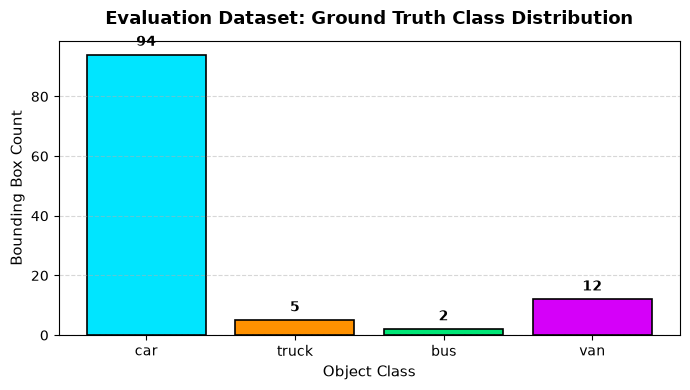

In [37]:
# 1. Table per image
summary_rows = []
for r in eval_records:
    counts = {CLASS_NAMES.get(cid, f"class_{cid}"): 0 for cid in sorted(CLASS_NAMES.keys())}
    for b in r["boxes"]:
        cname = b["class_name"]
        counts[cname] = counts.get(cname, 0) + 1
    
    row = {
        "Image": r["image_name"],
        "Resolution": f"{r['width']}x{r['height']}",
        "Total Boxes": r["num_boxes"],
        **counts
    }
    summary_rows.append(row)

df_summary = pd.DataFrame(summary_rows)
display(df_summary)

# 2. Total counts per class
total_counts = {CLASS_NAMES.get(cid, f"class_{cid}"): 0 for cid in sorted(CLASS_NAMES.keys())}
for r in eval_records:
    for b in r["boxes"]:
        total_counts[b["class_name"]] = total_counts.get(b["class_name"], 0) + 1

total_boxes_all = sum(total_counts.values())
df_classes = pd.DataFrame([
    {
        "Class ID": cid,
        "Class Name": name,
        "Box Count": total_counts[name],
        "Percentage": f"{(total_counts[name] / total_boxes_all * 100 if total_boxes_all else 0):.2f}%"
    }
    for cid, name in CLASS_NAMES.items()
])

print(f"\nTotal Bounding Boxes across eval set: {total_boxes_all}")
display(df_classes)

# 3. Plot class distribution bar chart
fig, ax = plt.subplots(figsize=(7, 4))
bar_colors = [CLASS_COLORS.get(cid, "#333333") for cid in CLASS_NAMES.keys()]
bars = ax.bar(df_classes["Class Name"], df_classes["Box Count"], color=bar_colors, edgecolor="black", linewidth=1.2)
ax.set_title("Evaluation Dataset: Ground Truth Class Distribution", fontsize=13, fontweight="bold", pad=12)
ax.set_ylabel("Bounding Box Count", fontsize=11)
ax.set_xlabel("Object Class", fontsize=11)
ax.grid(axis="y", linestyle="--", alpha=0.5)

for bar in bars:
    height = bar.get_height()
    ax.annotate(f"{height}",
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 4), textcoords="offset points",
                ha="center", va="bottom", fontweight="bold", fontsize=10)

plt.tight_layout()
plt.show()

## 4. Multi-Image Grid View (All 10 Evaluation Images)

Visualizes all 10 evaluation images in a 2x5 grid with ground-truth bounding boxes and colored class badges.

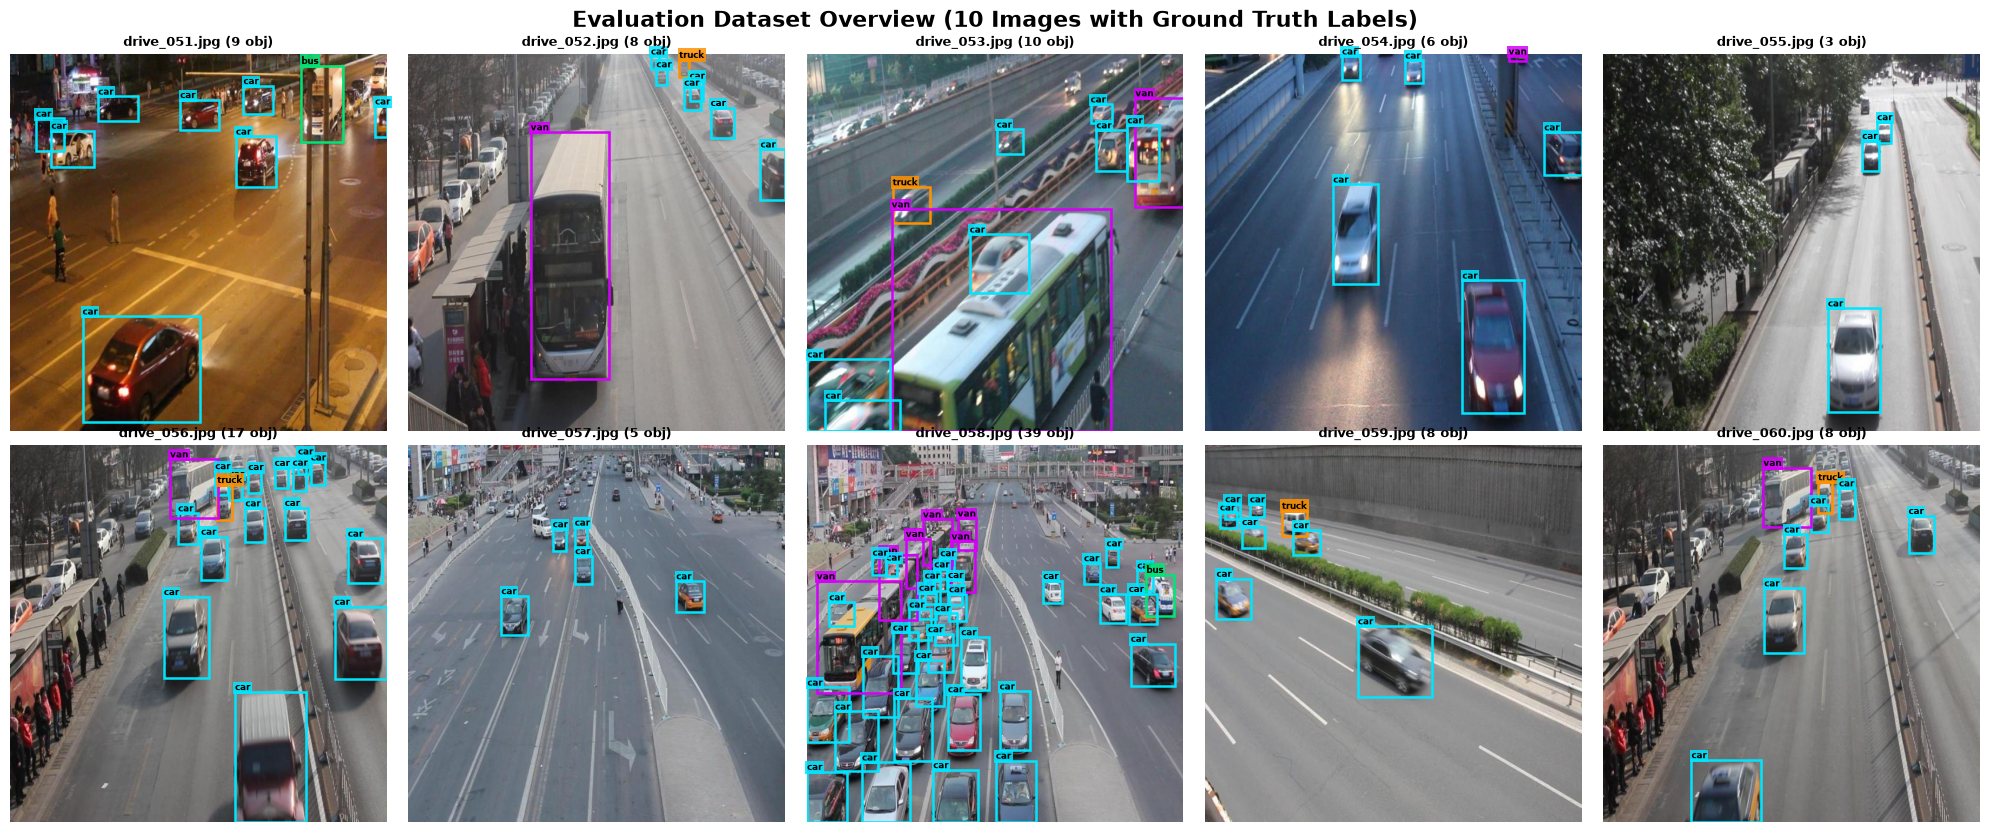

In [38]:
def draw_image_annotations(ax, record):
    """Draw image and ground truth bounding boxes on a matplotlib axis."""
    img = Image.open(record["image_path"])
    ax.imshow(img)
    
    for box in record["boxes"]:
        cid = box["class_id"]
        cname = box["class_name"]
        color = CLASS_COLORS.get(cid, "#FFFF00")
        
        # Bounding box rectangle
        rect = patches.Rectangle(
            (box["xmin"], box["ymin"]),
            box["box_w"],
            box["box_h"],
            linewidth=1.8,
            edgecolor=color,
            facecolor="none",
        )
        ax.add_patch(rect)
        
        # Class badge label
        ax.text(
            box["xmin"],
            max(0, box["ymin"] - 3),
            cname,
            bbox=dict(boxstyle="square,pad=0.18", facecolor=color, edgecolor="none", alpha=0.85),
            fontsize=6.5,
            fontweight="bold",
            color="black",
        )
    
    ax.set_title(f"{record['image_name']} ({record['num_boxes']} obj)", fontsize=9.5, fontweight="bold")
    ax.axis("off")

n_images = len(eval_records)
cols = 5
rows = int(np.ceil(n_images / cols))

fig, axes = plt.subplots(rows, cols, figsize=(20, 8.5))
axes = axes.flatten()

for i, record in enumerate(eval_records):
    draw_image_annotations(axes[i], record)

for j in range(n_images, len(axes)):
    axes[j].axis("off")

plt.suptitle("Evaluation Dataset Overview (10 Images with Ground Truth Labels)", fontsize=16, fontweight="bold", y=0.98)
plt.tight_layout()
plt.show()

## 5. Single-Image Detailed Inspector

Inspect any individual image at high resolution (set `image_idx_or_name` to an integer index `0..9` or image file name like `'drive_058.jpg'`).
Displays the annotated image along with an exact coordinates table.

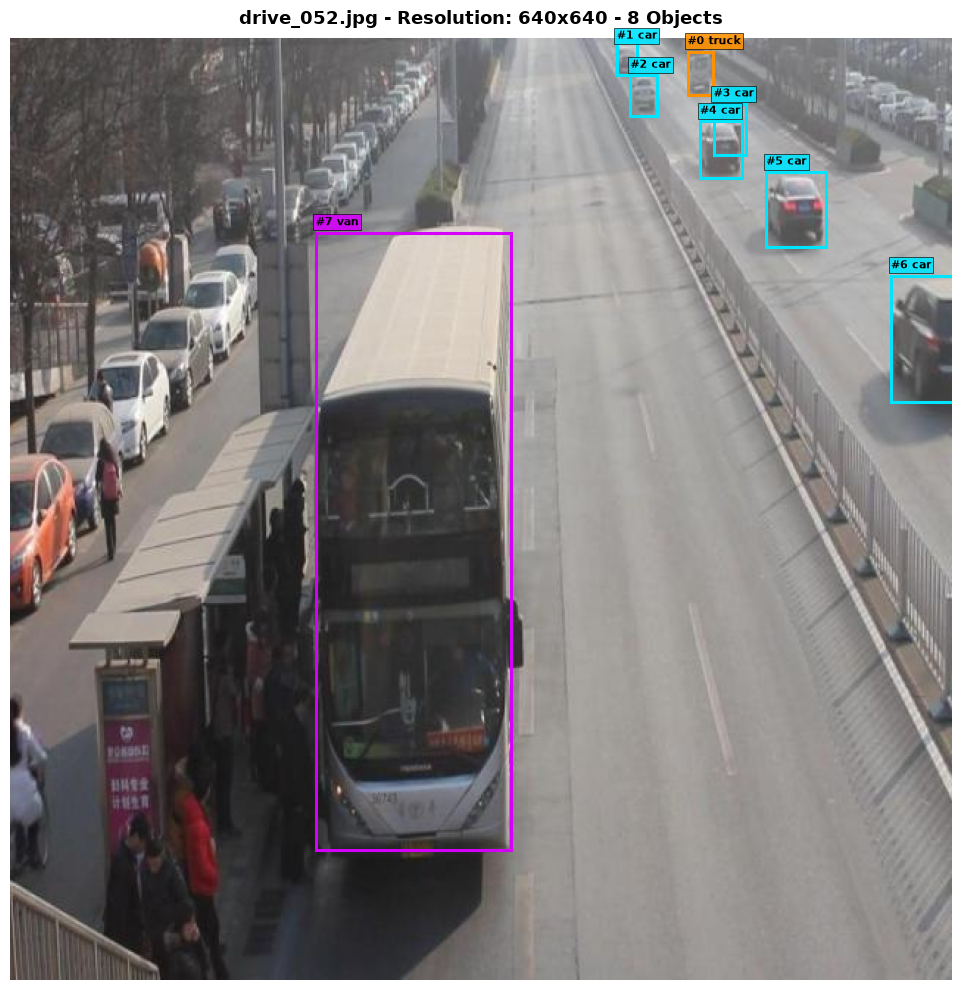


📋 Detailed Bounding Boxes for drive_052.jpg:


,#,Class,x_min,y_min,x_max,y_max,Width (px),Height (px),Area (px²),Area (%),"YOLO norm (xc, yc, w, h)"
0,0,truck (1),459.7,8.8,477.2,38.3,17.5,29.5,516.0,0.13%,"(0.7320, 0.0367, 0.0273, 0.0461)"
1,1,car (0),411.7,1.3,425.2,24.8,13.5,23.5,317.0,0.08%,"(0.6539, 0.0203, 0.0211, 0.0367)"
2,2,car (0),421.0,24.7,439.0,52.2,18.0,27.5,495.0,0.12%,"(0.6719, 0.0602, 0.0281, 0.0430)"
3,3,car (0),477.5,44.3,499.5,78.8,22.0,34.5,759.0,0.19%,"(0.7633, 0.0961, 0.0344, 0.0539)"
4,4,car (0),468.2,56.0,496.7,95.0,28.5,39.0,1111.0,0.27%,"(0.7539, 0.1180, 0.0445, 0.0609)"
5,5,car (0),513.3,90.5,553.8,141.5,40.5,51.0,2065.0,0.50%,"(0.8336, 0.1812, 0.0633, 0.0797)"
6,6,car (0),598.0,161.0,640.0,247.0,42.0,86.0,3612.0,0.88%,"(0.9672, 0.3187, 0.0656, 0.1344)"
7,7,van (3),207.3,131.8,339.8,551.3,132.5,419.5,55584.0,13.57%,"(0.4273, 0.5336, 0.2070, 0.6555)"


In [39]:
def inspect_image(image_idx_or_name=0):
    """Inspect a single evaluation image with detailed bounding box table."""
    if isinstance(image_idx_or_name, int):
        record = eval_records[image_idx_or_name]
    else:
        record = next((r for r in eval_records if r["image_name"] == image_idx_or_name or r["image_stem"] == image_idx_or_name), eval_records[0])
    
    # 1. Plot Large High-Resolution Image
    fig, ax = plt.subplots(figsize=(10, 10))
    img = Image.open(record["image_path"])
    ax.imshow(img)
    
    for box in record["boxes"]:
        cid = box["class_id"]
        cname = box["class_name"]
        color = CLASS_COLORS.get(cid, "#FFFF00")
        
        # Bounding box rectangle
        rect = patches.Rectangle(
            (box["xmin"], box["ymin"]),
            box["box_w"],
            box["box_h"],
            linewidth=2.2,
            edgecolor=color,
            facecolor="none",
        )
        ax.add_patch(rect)
        
        # Text label badge with box index
        label_text = f"#{box['box_idx']} {cname}"
        ax.text(
            box["xmin"],
            max(0, box["ymin"] - 5),
            label_text,
            bbox=dict(boxstyle="square,pad=0.22", facecolor=color, edgecolor="black", linewidth=0.5, alpha=0.9),
            fontsize=8,
            fontweight="bold",
            color="black",
        )
    
    ax.set_title(f"{record['image_name']} - Resolution: {record['width']}x{record['height']} - {record['num_boxes']} Objects", fontsize=13, fontweight="bold", pad=10)
    ax.axis("off")
    plt.tight_layout()
    plt.show()

    # 2. Display Detailed Bounding Box Table
    if record["boxes"]:
        df_boxes = pd.DataFrame([
            {
                "#": b["box_idx"],
                "Class": f"{b['class_name']} ({b['class_id']})",
                "x_min": round(b["xmin"], 1),
                "y_min": round(b["ymin"], 1),
                "x_max": round(b["xmax"], 1),
                "y_max": round(b["ymax"], 1),
                "Width (px)": round(b["box_w"], 1),
                "Height (px)": round(b["box_h"], 1),
                "Area (px²)": round(b["area_px"], 0),
                "Area (%)": f"{b['area_pct']:.2f}%",
                "YOLO norm (xc, yc, w, h)": f"({b['x_center']:.4f}, {b['y_center']:.4f}, {b['width_norm']:.4f}, {b['height_norm']:.4f})",
            }
            for b in record["boxes"]
        ])
        print(f"\n📋 Detailed Bounding Boxes for {record['image_name']}:")
        display(df_boxes)
    else:
        print(f"No objects annotated for {record['image_name']}.")

# Test with drive_051.jpg (index 0)
inspect_image(1)

## 6. Self-QC & Integrity Verification

Check that all 10 evaluation images and labels adhere to YOLO dataset standards:
- 1-to-1 match between images and `.txt` label files.
- Valid class IDs (`0, 1, 2, 3`).
- All normalized coordinates within `[0, 1]`.
- No boxes overflowing outside image boundaries.

In [40]:
def validate_eval_dataset(records):
    """Run integrity check on eval dataset labels."""
    errors = []
    total_boxes = 0
    valid_classes = set(CLASS_NAMES.keys())

    for r in records:
        if not r["label_path"].exists():
            errors.append(f"Missing label file: {r['label_path'].name}")
            continue

        for b in r["boxes"]:
            total_boxes += 1
            cid = b["class_id"]
            xc, yc, bw, bh = b["x_center"], b["y_center"], b["width_norm"], b["height_norm"]

            if cid not in valid_classes:
                errors.append(f"{r['image_name']}: invalid class_id {cid}")
            if not (0 <= xc <= 1 and 0 <= yc <= 1):
                errors.append(f"{r['image_name']}: center ({xc}, {yc}) out of [0, 1]")
            if bw <= 0 or bh <= 0:
                errors.append(f"{r['image_name']}: box has non-positive width/height ({bw}, {bh})")
            if (xc - bw / 2 < -1e-6) or (xc + bw / 2 > 1 + 1e-6) or (yc - bh / 2 < -1e-6) or (yc + bh / 2 > 1 + 1e-6):
                errors.append(f"{r['image_name']}: box boundaries exceed image frame")

    print("=" * 60)
    print("EVALUATION DATASET VALIDATION REPORT")
    print("=" * 60)
    print(f"Total Images: {len(records)}")
    print(f"Total Bounding Boxes: {total_boxes}")
    if not errors:
        print("STATUS: [PASSED] ALL EVAL LABELS ARE FULLY COMPLIANT")
    else:
        print(f"STATUS: [FAILED] ({len(errors)} issues found):")
        for err in errors[:10]:
            print(f"  - {err}")
    print("=" * 60)

validate_eval_dataset(eval_records)

EVALUATION DATASET VALIDATION REPORT
Total Images: 10
Total Bounding Boxes: 113
STATUS: [PASSED] ALL EVAL LABELS ARE FULLY COMPLIANT
